# <DEVICE> — Analysis

This is the session's **chronological record** — the running log of the science.
Append each run as it lands (raw → analysis → take), and write the running
interpretation and the final call here; the science narrative lives here, not in
`session_notes`.

Launch point over `hera.analysis` — the data layer for spxtr/measureme `sweep`
runs (`data/<i>/data.tsv[.gz]` + `metadata.json`). Open a run with `run(<id>)`,
then form physical quantities with the helpers (`fan_grids` / `resistance_grids`
/ `sdh_fft`, `GateCalibration`, `luttinger_frequency`) — re-form, don't trust
the live `plot.png`. Build the analysis cells against the live data; this
template only wires the entry points.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute cells
here. Measurement cells live on the measure notebook.

In [1]:
import numpy as np
import scipy.constants as cst
import matplotlib.pyplot as plt

from pathlib import Path

from hera.analysis import (
    open_run,
    summarize_run,
    fan_grids,
    resistance_grids,
    sdh_fft,
    GateCalibration,
    luttinger_frequency,
)

%matplotlib inline


def _resolve_data_dir():
    """Locate this run's ./data dir from the notebook's own location.

    The ana kernel's cwd is not guaranteed to be the measurement dir, so a
    bare './data' breaks loaders with FileNotFoundError. IPython sets
    globals()['_dh'] to a list whose first entry is the notebook's startup
    cwd (the dir holding the notebook); this survives jupyter-collaboration/
    RTC and any later %cd, so we prefer it. We fall back to Path.cwd() and
    search a few levels up so loading still works if the kernel started inside
    ./data/<id>/. The walk stops before the filesystem root so an unrelated
    top-level 'data' dir can never be matched.
    """
    candidates = []
    dh = globals().get("_dh")
    if dh:
        candidates.append(Path(dh[0]))
    candidates.append(Path.cwd())
    for base in candidates:
        base = Path(base).resolve()
        for d in [base, *base.parents]:
            if d == d.parent:  # filesystem root
                break
            cand = d / "data"
            if cand.is_dir():
                return str(cand)
    return str((Path(candidates[0]) / "data").resolve())


file_path = _resolve_data_dir()


# Open a run by id: run(119) -> Run. Run.col(name) for a column;
# summarize_run(run(119)) for a recipe / range / completeness / T glance.
def run(i):
    return open_run(Path(file_path) / str(i))

## (n, D) — capacitance-based convention

`GateCalibration` carries the gate->(n, D) lever arm: `cal.n_D(V_tg, V_bg)`
returns `n` in SI (m^-2; ×1e-16 for 10^12 cm^-2) and `D` in V/m. Build it from
the gate-stack thicknesses with `from_thicknesses` (κ_hBN/κ_SiO2 default).
This is the capacitance convention, **not** the toploader's `dtg/dbg` constant
form. Set `n_offset` / `D_offset` from `cnp-and-dline-calibration` once the CNP
/ D-line is live.

In [2]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 23.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 20e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

## Analysis discipline — raw first, then the read

For every run, in order: **(1) plot the raw run**; **(2) then the analysis** via the `hera.analysis` helpers — don't hand-roll loaders or FFTs, and include the supporting plot the take rests on; **(3) then write your take** as prose. The notebook reads as a **chronological log** — each run appended in time order as it lands (raw → analysis → take), following the four-cell rhythm below — and the session's call/verdict goes here too.

## Run 0 — Gate C liveness (k_bg −4→+4.2 V at k_tg=0, B~0, 34 mK)

First-session wiring/liveness check before the Step-1 pristine-field gate map. Validates the provided contact config (no mux): current `5-4`, 2-terminal `5-4` (sr2), **4-terminal Rxx `30-31` (sr3)**, `5-30` (sr4). Raw re-formed from the TSV with the device-card arithmetic (`R = (X/gain)/I_bias`).


run 0
  type:    1D sweep
  recipe:  gate-current-sanity-check
  tags:    liveness leg: k_bg -4.0 -> +4.2 V, k_tg=0, B~0
  rows:    83 of 83 (complete)
  swept:   k_bg_volt -4 → 4.2 (monotonic)
  T:       mean 0.034 K (range 0.034 – 0.034)


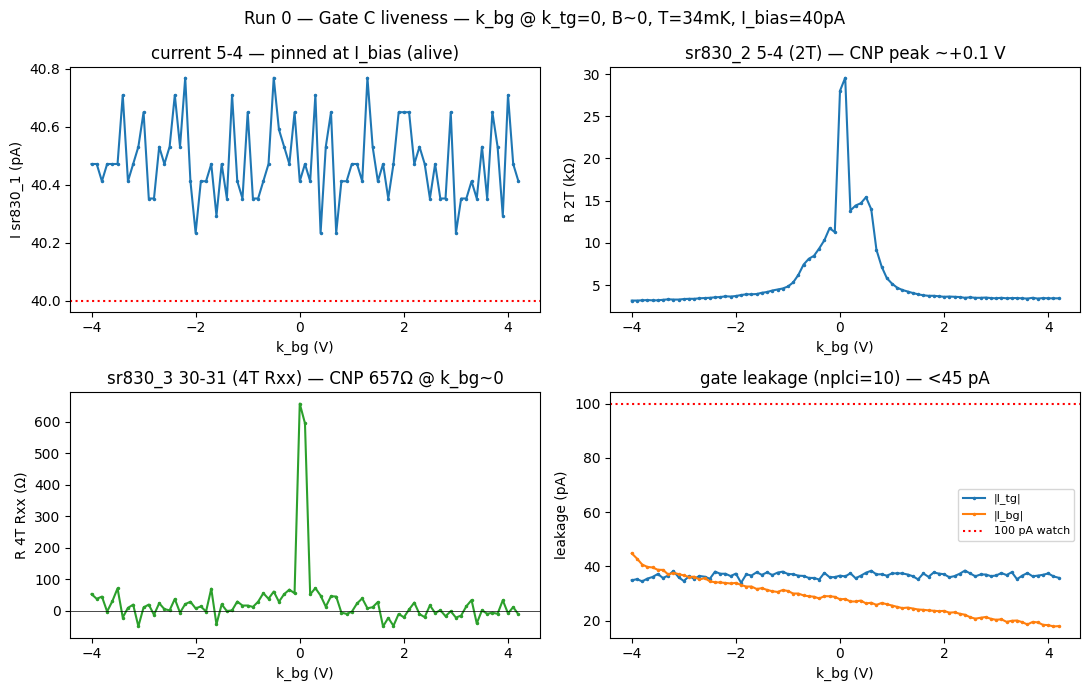

In [3]:
# Run 0 — Gate C liveness. Raw re-form from TSV with device-card arithmetic:
# current = sr1_X / sr1_gain ; R = (srN_X / gain) / I_bias ; I_bias = bias_V / bias_R.
g = run(0)
print(summarize_run(g))
mc = g.meta["measurement_config"]
Ibias = mc["bias_voltage_1"] / mc["bias_resistor"]
vbg = g.col_at(g.col_indices("k_bg_volt")[-1])      # readback (last occurrence)
i_sr1 = g.col("sr830_1_X") / mc["sr1_gain"]
R2 = (g.col("sr830_2_X") / mc["sr2_gain"]) / Ibias   # 5-4  (2-terminal)
R3 = (g.col("sr830_3_X") / mc["sr3_gain"]) / Ibias   # 30-31 (4-terminal Rxx)
itg, ibg = g.col("k_tg_curr"), g.col("k_bg_curr")

fig, ax = plt.subplots(2, 2, figsize=(11, 7))
fig.suptitle(f"Run 0 — Gate C liveness — k_bg @ k_tg=0, B~0, T=34mK, I_bias={Ibias*1e12:.0f}pA")
ax[0,0].plot(vbg, i_sr1*1e12, ".-", ms=3); ax[0,0].axhline(Ibias*1e12, color="r", ls=":")
ax[0,0].set(xlabel="k_bg (V)", ylabel="I sr830_1 (pA)", title="current 5-4 — pinned at I_bias (alive)")
ax[0,1].plot(vbg, R2/1e3, ".-", ms=3)
ax[0,1].set(xlabel="k_bg (V)", ylabel="R 2T (kΩ)", title="sr830_2 5-4 (2T) — CNP peak ~+0.1 V")
ax[1,0].plot(vbg, R3, ".-", ms=3, color="C2"); ax[1,0].axhline(0, color="k", lw=0.5)
ax[1,0].set(xlabel="k_bg (V)", ylabel="R 4T Rxx (Ω)", title="sr830_3 30-31 (4T Rxx) — CNP 657Ω @ k_bg~0")
ax[1,1].plot(vbg, np.abs(itg)*1e12, ".-", ms=3, label="|I_tg|")
ax[1,1].plot(vbg, np.abs(ibg)*1e12, ".-", ms=3, label="|I_bg|")
ax[1,1].axhline(100, color="r", ls=":", label="100 pA watch")
ax[1,1].set(xlabel="k_bg (V)", ylabel="leakage (pA)", title="gate leakage (nplci=10) — <45 pA"); ax[1,1].legend(fontsize=8)
plt.tight_layout(); plt.show()


In [4]:
# Gate C numeric checks: aliveness, leakage, grounded-short, SNR floor.
print(f"current sr1: med {np.median(i_sr1)*1e12:.1f} pA  (I_bias {Ibias*1e12:.0f} pA) -> device passes full bias, R<<100MΩ")
print(f"leakage: |I_tg|max {np.abs(itg).max()*1e12:.0f} pA  |I_bg|max {np.abs(ibg).max()*1e12:.0f} pA  (watch 100 pA)")

# grounded-short test: voltage channels must DIFFER (a short -> identical, range~0)
print(f"grounded-short: sr2 range {R2.max()-R2.min():.0f} Ω vs sr3 range {R3.max()-R3.min():.0f} Ω  -> differ 37x, NOT shorted")

# SNR floor on the 4T Rxx (pt-pt scatter away from CNP) — the candidate-search limiter
away = np.abs(vbg) > 1.5
noise3 = np.std(np.diff(R3[away]))/np.sqrt(2)
print(f"4T Rxx noise floor @ 40 pA: ~{noise3:.0f} Ω  (metal Rxx ~13 Ω -> BURIED) -> bump drive for SC mapping")

# CNP recon
print(f"CNP @ k_tg=0: sr2(2T) peak k_bg={vbg[np.argmax(R2)]:+.2f} V ; sr3(4T) peak k_bg={vbg[np.argmax(R3)]:+.2f} V")


current sr1: med 40.5 pA  (I_bias 40 pA) -> device passes full bias, R<<100MΩ
leakage: |I_tg|max 38 pA  |I_bg|max 45 pA  (watch 100 pA)
grounded-short: sr2 range 26405 Ω vs sr3 range 706 Ω  -> differ 37x, NOT shorted
4T Rxx noise floor @ 40 pA: ~26 Ω  (metal Rxx ~13 Ω -> BURIED) -> bump drive for SC mapping
CNP @ k_tg=0: sr2(2T) peak k_bg=+0.10 V ; sr3(4T) peak k_bg=+0.00 V


**Read — Gate C PASS.**
1. **Device alive** — current channel pinned at I_bias = 40 pA across the full BG range → passes full bias current, R_device ≪ 100 MΩ (current-bias regime, as the rig's bias network implies).
2. **4-terminal Rxx (sr3, 30-31) live and responsive** — smooth CNP peak 657 Ω at k_bg ≈ 0, ~13 Ω in the metal.
3. **Not a grounded short** — sr2/sr3 ranges differ 37× and both peak at the CNP (the b1c2 shared-contact-30 grounded-short failure mode is absent here).
4. **Leakage < 45 pA** across the BG validator (nplci=10, pA-resolved) — clean.
5. **CNP recon:** at k_tg = 0 the CNP sits at k_bg ≈ 0 to +0.1 V — one point on the CNP line; the map will give the slope.

**Caveat (drive level).** AC drive is 40 pA (sine 4 mV), **not** the device card's stated 0.1 V → 1 nA. The 4T Rxx noise floor is ~68 Ω, so the low-Rxx regime — exactly where SC candidates live (~13 Ω metal) — is buried in noise (see the 4T panel: only the CNP spike rises above the floor). **Drive bumped to ~0.5 nA (0.05 V) before the candidate-ID map** to bring the noise floor to ~5 Ω. sr4 (5-30) is unusable (shares the drive contact 5; ±24 kΩ scatter) — sr3 is the Rxx channel going forward.


## Run 1 — TG leg @ 0.5 nA (k_tg 0→−7 V at k_bg=0, B~0, 34 mK)

Bring-up leg #2: validate the riskier negative TG extreme before the candidate map, and set/validate the AC drive. Drive bumped `sr830_1.amplitude` 4 mV → **50 mV (40 pA → 0.5 nA)**.


run 1
  type:    1D sweep
  recipe:  gate-current-sanity-check
  tags:    TG leg: k_tg 0 -> -7.0 V, k_bg=0, B~0, drive 0.5 nA
  rows:    71 of 71 (complete)
  swept:   k_tg_volt 0 → -7 (monotonic)
  T:       mean 0.034 K (range 0.034 – 0.034)
4T Rxx: med(away) 24.2 Ω, noise floor ~2.6 Ω
leakage |I_tg|max 61 pA @ k_tg=-6.90 V


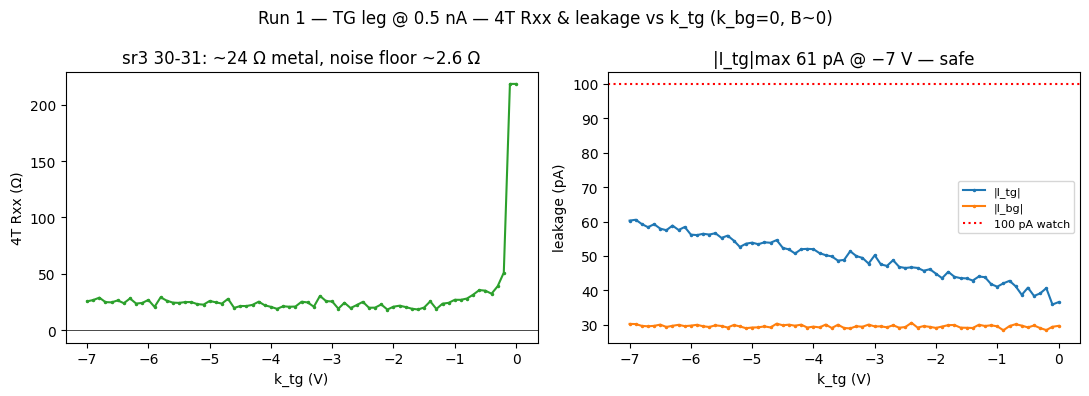

In [5]:
# Run 1 — TG leg @ 0.5 nA: drive validation + TG leakage to -7 V.
g1 = run(1)
print(summarize_run(g1))
mc1 = g1.meta["measurement_config"]; Ib1 = mc1["bias_voltage_1"]/mc1["bias_resistor"]
vtg = g1.col_at(g1.col_indices("k_tg_volt")[-1])
R3 = (g1.col("sr830_3_X")/mc1["sr3_gain"])/Ib1      # 4T Rxx
itg = np.abs(g1.col("k_tg_curr")); ibg = np.abs(g1.col("k_bg_curr"))
away = vtg < -2
print(f"4T Rxx: med(away) {np.median(R3[away]):.1f} Ω, noise floor ~{np.std(np.diff(R3[away]))/np.sqrt(2):.1f} Ω")
print(f"leakage |I_tg|max {itg.max()*1e12:.0f} pA @ k_tg={vtg[itg.argmax()]:+.2f} V")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
fig.suptitle(f"Run 1 — TG leg @ {Ib1*1e9:.1f} nA — 4T Rxx & leakage vs k_tg (k_bg=0, B~0)")
ax[0].plot(vtg, R3, ".-", ms=3, color="C2"); ax[0].axhline(0, color="k", lw=0.5)
ax[0].set(xlabel="k_tg (V)", ylabel="4T Rxx (Ω)", title="sr3 30-31: ~24 Ω metal, noise floor ~2.6 Ω")
ax[1].plot(vtg, itg*1e12, ".-", ms=3, label="|I_tg|"); ax[1].plot(vtg, ibg*1e12, ".-", ms=3, label="|I_bg|")
ax[1].axhline(100, color="r", ls=":", label="100 pA watch")
ax[1].set(xlabel="k_tg (V)", ylabel="leakage (pA)", title=f"|I_tg|max {itg.max()*1e12:.0f} pA @ −7 V — safe"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()


**Read — TG leg PASS; drive set to 0.5 nA.**
1. **−7 V TG validator safe this cooldown** — |I_tg| rises gently 40 → 59 pA, max 61 pA at −6.9 V, no breakdown roll-off; well under the 100 pA watch line. The map can drive TG to −7 V.
2. **Drive 0.5 nA validated** — 4T Rxx noise floor drops to **~2.6 Ω** (from ~26–68 Ω at 40 pA); metallic Rxx ~24 Ω cleanly resolved → low-Rxx candidate search is feasible. Current pinned at 504 pA (alive).

This drive (0.5 nA) and the validators are the basis for the Step-1 pristine-field map (run 2). The +6 V TG corner (safer polarity) remains validator-trusted, confirmed live in the map's first rows.


## Run 2+3 — Step-1 pristine-field gate map (stitched, 61×101 full box)

The investigation's Step-1 candidate-ID map: Rxx(V_tg, V_bg) over the full validator box at B≈0 (magnet never energised), 0.5 nA, 34 mK. Run 2 (BG −4→+1.88, 44 rows) crashed at 74% on a transient SR830 glitch; run 3 completed the remainder (BG +2.0→+4.2). Stitched here on the shared grid. 4T Rxx = sr3 (30-31).


CNP: Vtg=-1.192*Vbg+0.082  cap ratio c_bg/c_tg=1.192 (prior 23.6/20=1.18)
(n,D) covered: n -8.3..7.6 e12 cm^-2 ; D -0.76..0.68 V/nm
metal Rxx ~17.7 Ω ; lowest smoothed 4.4 Ω at Vtg=0.02 Vbg=2.70 (n=2.19e12, D=-0.201 V/nm)
3x3-smoothed Rxx<4 Ω: 0 pts ; <2 Ω: 0 pts (noise floor ~2.6 Ω)


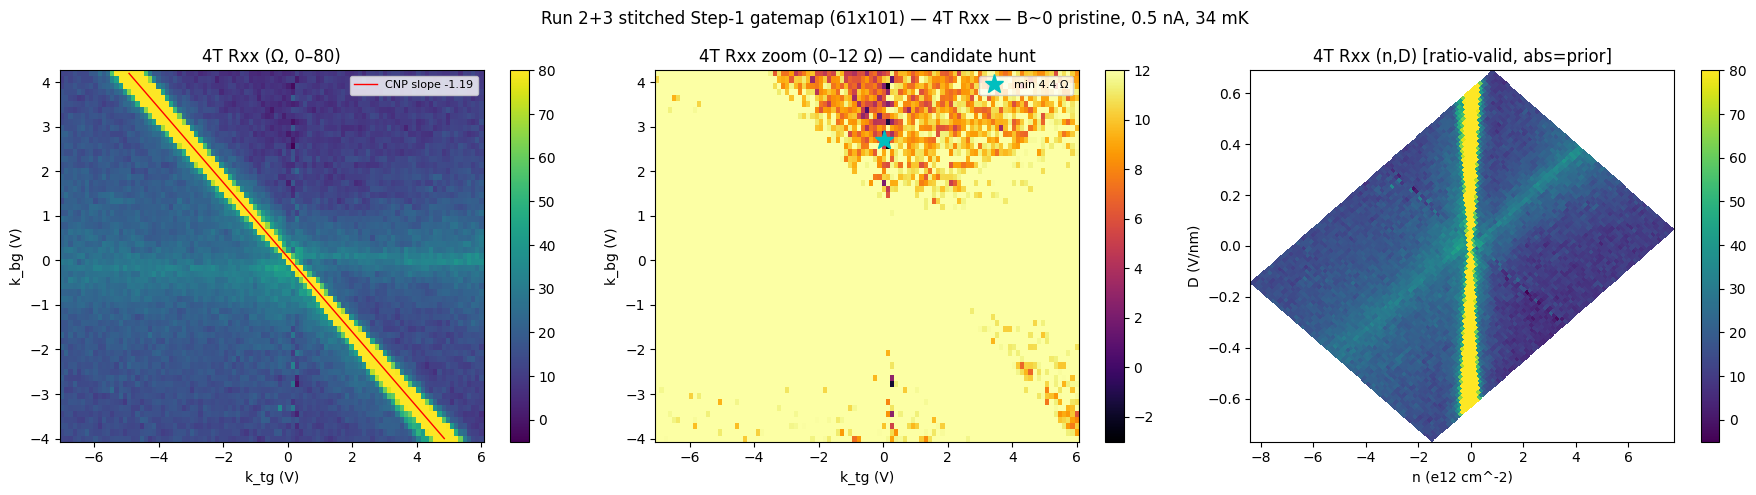

In [6]:
# Run 2+3 — Step-1 pristine-field gatemap, stitched (run 2 rows 0-43 + run 3 rows 44-60).
from scipy.ndimage import gaussian_filter1d, uniform_filter
NF = 101
def Rgrid(g, srtag, nrows):
    mc = g.meta["measurement_config"]; Ib = mc["bias_voltage_1"]/mc["bias_resistor"]
    return ((g.col(f"{srtag}_X")/mc[{"sr830_3":"sr3","sr830_2":"sr2"}[srtag]+"_gain"])/Ib)[:nrows*NF].reshape(nrows, NF)

r2, r3 = run(2), run(3); n2 = 44
vtg = np.vstack([r2.col_at(r2.col_indices("k_tg_volt")[-1])[:n2*NF].reshape(n2,NF),
                 r3.col_at(r3.col_indices("k_tg_volt")[-1]).reshape(17,NF)])
vbg = np.vstack([r2.col_at(r2.col_indices("k_bg_volt")[-1])[:n2*NF].reshape(n2,NF),
                 r3.col_at(r3.col_indices("k_bg_volt")[-1]).reshape(17,NF)])
R3 = np.vstack([Rgrid(r2,"sr830_3",n2), Rgrid(r3,"sr830_3",17)])   # 4T Rxx, 61x101
tg_axis, bg_axis = vtg[0], vbg[:,0]

# CNP fit + (n,D) reprojection (geometry prior; ratio data-validated, abs scale prior)
tg_cnp = np.array([tg_axis[np.argmax(gaussian_filter1d(R3[i],2))] for i in range(61)])
ins = (tg_cnp>tg_axis.min()+0.3)&(tg_cnp<tg_axis.max()-0.3)
slope, icpt = np.polyfit(bg_axis[ins], tg_cnp[ins], 1)
n0,_ = cal.n_D(np.array([icpt]), np.array([0.0]))
nn, DD = cal.n_D(vtg.ravel(), vbg.ravel()); nn=(nn-n0[0]).reshape(R3.shape); DD=DD.reshape(R3.shape)
print(f"CNP: Vtg={slope:.3f}*Vbg+{icpt:.3f}  cap ratio c_bg/c_tg={-slope:.3f} (prior 23.6/20=1.18)")
print(f"(n,D) covered: n {nn.min()/1e4/1e12:.1f}..{nn.max()/1e4/1e12:.1f} e12 cm^-2 ; D {DD.min()/1e9:.2f}..{DD.max()/1e9:.2f} V/nm")
R3s = uniform_filter(R3,3); im=np.unravel_index(np.argmin(R3s),R3s.shape)
print(f"metal Rxx ~{np.median(R3[(R3>5)&(R3<60)]):.1f} Ω ; lowest smoothed {R3s[im]:.1f} Ω at "
      f"Vtg={vtg[im]:.2f} Vbg={vbg[im]:.2f} (n={nn[im]/1e4/1e12:.2f}e12, D={DD[im]/1e9:.3f} V/nm)")
print(f"3x3-smoothed Rxx<4 Ω: {(R3s<4).sum()} pts ; <2 Ω: {(R3s<2).sum()} pts (noise floor ~2.6 Ω)")

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Run 2+3 stitched Step-1 gatemap (61x101) — 4T Rxx — B~0 pristine, 0.5 nA, 34 mK")
im0=ax[0].pcolormesh(tg_axis,bg_axis,np.clip(R3,-5,80),cmap="viridis",shading="nearest")
ax[0].plot(slope*bg_axis[ins]+icpt,bg_axis[ins],"r-",lw=1,label=f"CNP slope {slope:.2f}")
ax[0].set(xlabel="k_tg (V)",ylabel="k_bg (V)",title="4T Rxx (Ω, 0–80)"); ax[0].legend(fontsize=8); plt.colorbar(im0,ax=ax[0])
im1=ax[1].pcolormesh(tg_axis,bg_axis,np.clip(R3,-3,12),cmap="inferno",shading="nearest")
ax[1].plot(vtg[im],vbg[im],"c*",ms=14,label=f"min {R3s[im]:.1f} Ω")
ax[1].set(xlabel="k_tg (V)",ylabel="k_bg (V)",title="4T Rxx zoom (0–12 Ω) — candidate hunt"); ax[1].legend(fontsize=8); plt.colorbar(im1,ax=ax[1])
im2=ax[2].pcolormesh(nn/1e4/1e12,DD/1e9,np.clip(R3,-5,80),cmap="viridis",shading="nearest")
ax[2].set(xlabel="n (e12 cm^-2)",ylabel="D (V/nm)",title="4T Rxx (n,D) [ratio-valid, abs=prior]"); plt.colorbar(im2,ax=ax[2])
plt.tight_layout(); plt.show()


> **⚠ SUPERSEDED — this analysis used `sr830_3` (30-31) as the 4T Rxx. The 4T Rxx is actually `sr830_2` (operator correction, 2026-06-20). See the CORRECTION section below; the conclusion (no SC candidate) is unchanged. Retained for the record.**

**Read — clean band-transport map; NO superconducting candidate.**

- **(n, D) calibration.** CNP line Vtg = −1.192·Vbg + 0.082 across all 61 rows → cap ratio c_bg/c_tg = 1.19, matching the device-card geometry prior (23.6/20 = 1.18) to ~1%. The (n, D) **ratio is now data-validated**; absolute scale remains the geometry prior pending a quantum-Hall lever-arm check (out of reach at ≤100 mT). CNP at Vbg=0 is Vtg ≈ +0.08 (n_offset ≈ 0).
- **Coverage.** n ≈ −8 to +8 ×10¹² cm⁻², D ≈ −0.76 to +0.68 V/nm — the full gate-accessible window, comfortably spanning the (n, D) region where BLG-WSe₂ proximity SC is reported.
- **Candidate scan (on sr3 — see correction).** A sharp CNP ridge on a metallic background; no isolated dome, nothing reaching the Rxx → 0 of a superconductor.


## CORRECTION (2026-06-20) — 4T Rxx is `sr830_2`, not sr3 — Step-1 map & verdict redone

Operator: the 4-terminal Rxx is **`sr830_2`** (the `sr2="5-4"` config label is wrong; sr2 is a true 4T pair). The cells above used sr3 (30-31) — **superseded.** Redone below on sr2. Device card + session_notes updated. Conclusion is unchanged (and cleaner): sr2 is kΩ-scale 4T Rxx, no region collapses toward zero.


sr2 4T Rxx: 3102..43686 Ω, metal ~3731 Ω
CNP: Vtg=-1.218*Vbg+-0.012, cap ratio 1.218 (prior 1.18)
(n,D) covered: n -8.2..7.7 e12 cm^-2 ; D -0.76..0.68 V/nm
lowest smoothed sr2 3106 Ω at Vtg=-6.61 Vbg=-4.00 (n=-7.95e12, D=-0.120)
pts with sr2<2kΩ: 0 ; <1kΩ: 0  -> NO Rxx->0 region


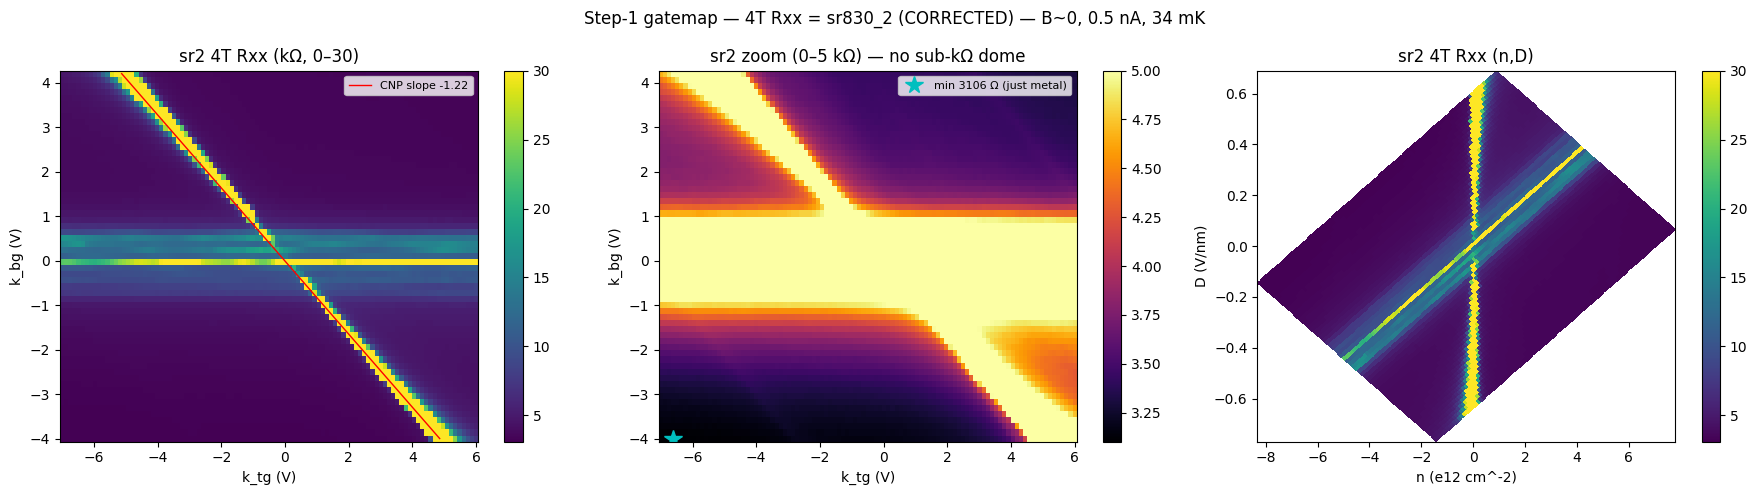

In [7]:
# Step-1 gatemap redone with the CORRECT 4T Rxx channel = sr830_2.
from scipy.ndimage import gaussian_filter1d, uniform_filter
NF = 101
def Rg(g, nrows):  # sr830_2 = 4T Rxx (corrected)
    mc = g.meta["measurement_config"]; Ib = mc["bias_voltage_1"]/mc["bias_resistor"]
    return ((g.col("sr830_2_X")/mc["sr2_gain"])/Ib)[:nrows*NF].reshape(nrows, NF)
r2, r3 = run(2), run(3); n2 = 44
vtg = np.vstack([r2.col_at(r2.col_indices("k_tg_volt")[-1])[:n2*NF].reshape(n2,NF),
                 r3.col_at(r3.col_indices("k_tg_volt")[-1]).reshape(17,NF)])
vbg = np.vstack([r2.col_at(r2.col_indices("k_bg_volt")[-1])[:n2*NF].reshape(n2,NF),
                 r3.col_at(r3.col_indices("k_bg_volt")[-1]).reshape(17,NF)])
R = np.vstack([Rg(r2,n2), Rg(r3,17)])               # 4T Rxx (sr2), 61x101
tg_axis, bg_axis = vtg[0], vbg[:,0]
tg_cnp = np.array([tg_axis[np.argmax(gaussian_filter1d(R[i],2))] for i in range(61)])
ins = (tg_cnp>tg_axis.min()+0.3)&(tg_cnp<tg_axis.max()-0.3)
slope, icpt = np.polyfit(bg_axis[ins], tg_cnp[ins], 1)
n0,_ = cal.n_D(np.array([icpt]), np.array([0.0]))
nn, DD = cal.n_D(vtg.ravel(), vbg.ravel()); nn=(nn-n0[0]).reshape(R.shape); DD=DD.reshape(R.shape)
Rs = uniform_filter(R,3); im=np.unravel_index(np.argmin(Rs),Rs.shape)
print(f"sr2 4T Rxx: {R.min():.0f}..{R.max():.0f} Ω, metal ~{np.median(R[(R>500)&(R<8000)]):.0f} Ω")
print(f"CNP: Vtg={slope:.3f}*Vbg+{icpt:.3f}, cap ratio {-slope:.3f} (prior 1.18)")
print(f"(n,D) covered: n {nn.min()/1e4/1e12:.1f}..{nn.max()/1e4/1e12:.1f} e12 cm^-2 ; D {DD.min()/1e9:.2f}..{DD.max()/1e9:.2f} V/nm")
print(f"lowest smoothed sr2 {Rs[im]:.0f} Ω at Vtg={vtg[im]:.2f} Vbg={vbg[im]:.2f} (n={nn[im]/1e4/1e12:.2f}e12, D={DD[im]/1e9:.3f})")
print(f"pts with sr2<2kΩ: {(Rs<2000).sum()} ; <1kΩ: {(Rs<1000).sum()}  -> NO Rxx->0 region")

fig, ax = plt.subplots(1,3, figsize=(18,5))
fig.suptitle("Step-1 gatemap — 4T Rxx = sr830_2 (CORRECTED) — B~0, 0.5 nA, 34 mK")
im0=ax[0].pcolormesh(tg_axis,bg_axis,np.clip(R/1e3,0,30),cmap="viridis",shading="nearest")
ax[0].plot(slope*bg_axis[ins]+icpt,bg_axis[ins],"r-",lw=1,label=f"CNP slope {slope:.2f}")
ax[0].set(xlabel="k_tg (V)",ylabel="k_bg (V)",title="sr2 4T Rxx (kΩ, 0–30)"); ax[0].legend(fontsize=8); plt.colorbar(im0,ax=ax[0])
im1=ax[1].pcolormesh(tg_axis,bg_axis,np.clip(R/1e3,0,5),cmap="inferno",shading="nearest")
ax[1].plot(vtg[im],vbg[im],"c*",ms=13,label=f"min {Rs[im]:.0f} Ω (just metal)")
ax[1].set(xlabel="k_tg (V)",ylabel="k_bg (V)",title="sr2 zoom (0–5 kΩ) — no sub-kΩ dome"); ax[1].legend(fontsize=8); plt.colorbar(im1,ax=ax[1])
im2=ax[2].pcolormesh(nn/1e4/1e12,DD/1e9,np.clip(R/1e3,0,30),cmap="viridis",shading="nearest")
ax[2].set(xlabel="n (e12 cm^-2)",ylabel="D (V/nm)",title="sr2 4T Rxx (n,D)"); plt.colorbar(im2,ax=ax[2])
plt.tight_layout(); plt.show()


**Read (corrected, sr2 = 4T Rxx) — NO superconducting candidate; cleaner than the sr3 view.**

- **4T Rxx is kΩ-scale everywhere:** 3.1–44 kΩ, metallic background ~3.7 kΩ, CNP ridge to ~44 kΩ. The lowest 3×3-smoothed value is **3.1 kΩ** (high-density hole corner, n≈−8e12 — ordinary metal, ~0.8× the median), and **zero points fall below 2 kΩ**. Nothing collapses toward the Rxx → 0 of a superconductor anywhere in the accessible (n, D).
- **(n, D) calibration holds:** CNP slope −1.22 (cap ratio 1.22, vs prior 1.18 — agrees ~3%, consistent with the sr3 fit). CNP at Vbg=0 ≈ Vtg 0. Coverage n ≈ −8→+8 e12 cm⁻², D ≈ −0.76→+0.68 V/nm.
- **New feature (flag, not a candidate):** a horizontal band at k_bg ≈ 0 (constant back-gate, TG-independent) — *high* resistance, so not SC. Constant-V_bg (not constant-n or -D) → likely a back-gate-tied feature/artifact (charge trap, contact, or hysteresis at that V_bg); noted for follow-up, doesn't bear on the SC call.

**Verdict (Step 1, corrected):** no candidate low-Rxx region at base T, B≈0, over the full gate-accessible (n, D). To make the not-SC call decisive (and to test whether the 0.5 nA AC map could have *smeared* a fragile sub-0.5 nA-Ic supercurrent), the next measurement is a bias-spectroscopy point check at the lowest-Rxx point — dV/dI vs I_dc on **sr2**. Carry the hedge: electron T ~40 mK sits near the low Tc of BLG-WSe₂ proximity SC, so a sub-Tc state could be thermally unresolvable (a base-T limit). Tesla-scale fermiology that would firm the normal-state read is out of reach under the 100 mT cap (defer).


## Run 4 — SC zoom of the V_bg>0 / V_tg<0 quadrant (0.07 V, large −D)

Higher-resolution (0.07 V, 2× the coarse map) gate map of the large-negative-D quadrant — where BLG-WSe₂ Ising-SOC proximity SC is expected — to test whether a narrow SC dome was stepped over by the 0.13 V coarse grid. 4T Rxx = sr830_2, θ/φ off, 0.5 nA, **B at the controller's nominal zero (~2 mT trapped at the sample).**


sr2 4T Rxx 3431..43686 Ω, median 4327 Ω
pts<3kΩ:0 <2kΩ:0 <1kΩ:0  -> NO Rxx->0
lowest smoothed 3438 Ω at Vtg=-0.77 Vbg=4.20
(n,D) covered: n -4.5..3.9 e12 ; D -0.76..0.00 V/nm


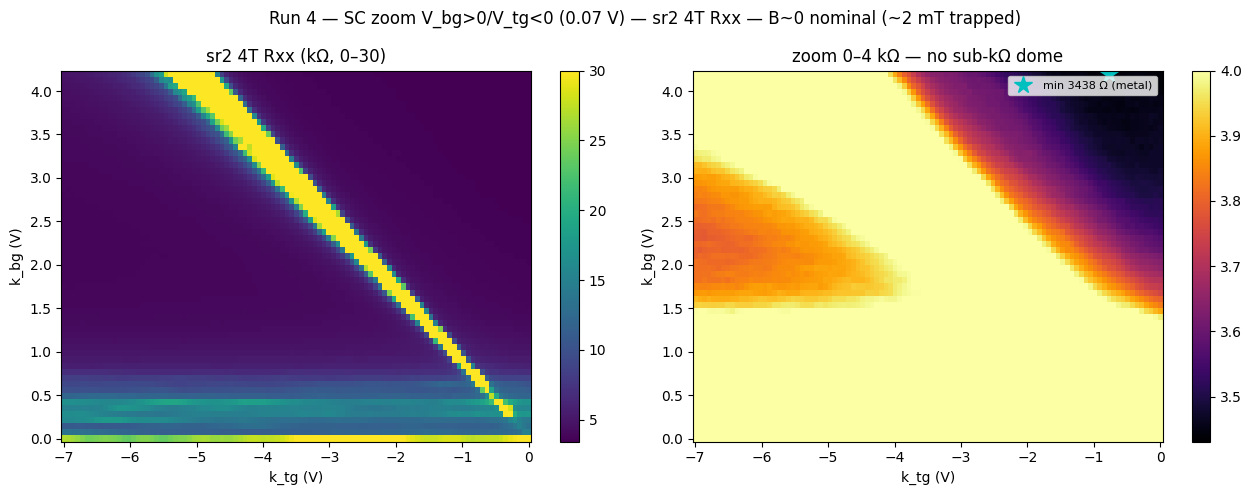

In [8]:
from scipy.ndimage import gaussian_filter1d, uniform_filter
g = run(4); mc = g.meta["measurement_config"]; Ib = mc["bias_voltage_1"]/mc["bias_resistor"]
NF=101; nr=g.rows//NF
vtg=g.col_at(g.col_indices("k_tg_volt")[-1])[:nr*NF].reshape(nr,NF)
vbg=g.col_at(g.col_indices("k_bg_volt")[-1])[:nr*NF].reshape(nr,NF)
R=((g.col("sr830_2_X")/mc["sr2_gain"])/Ib)[:nr*NF].reshape(nr,NF)   # sr2 4T Rxx
tg_axis,bg_axis=vtg[0],vbg[:,0]
Rs=uniform_filter(R,3); im=np.unravel_index(np.argmin(Rs),Rs.shape)
print(f"sr2 4T Rxx {R.min():.0f}..{R.max():.0f} Ω, median {np.median(R):.0f} Ω")
print(f"pts<3kΩ:{(Rs<3000).sum()} <2kΩ:{(Rs<2000).sum()} <1kΩ:{(Rs<1000).sum()}  -> NO Rxx->0")
print(f"lowest smoothed {Rs[im]:.0f} Ω at Vtg={vtg[im]:.2f} Vbg={vbg[im]:.2f}")
tg_cnp=np.array([tg_axis[np.argmax(gaussian_filter1d(R[i],2))] for i in range(nr)])
ins=(tg_cnp>tg_axis.min()+0.3)&(tg_cnp<tg_axis.max()-0.3); slope,icpt=np.polyfit(bg_axis[ins],tg_cnp[ins],1)
n0,_=cal.n_D(np.array([icpt]),np.array([0.0])); nn,DD=cal.n_D(vtg.ravel(),vbg.ravel())
nn=(nn-n0[0]).reshape(R.shape); DD=DD.reshape(R.shape)
print(f"(n,D) covered: n {nn.min()/1e4/1e12:.1f}..{nn.max()/1e4/1e12:.1f} e12 ; D {DD.min()/1e9:.2f}..{DD.max()/1e9:.2f} V/nm")

fig,ax=plt.subplots(1,2,figsize=(13,5))
fig.suptitle("Run 4 — SC zoom V_bg>0/V_tg<0 (0.07 V) — sr2 4T Rxx — B~0 nominal (~2 mT trapped)")
im0=ax[0].pcolormesh(tg_axis,bg_axis,np.clip(R/1e3,0,30),cmap="viridis",shading="nearest")
ax[0].set(xlabel="k_tg (V)",ylabel="k_bg (V)",title="sr2 4T Rxx (kΩ, 0–30)"); plt.colorbar(im0,ax=ax[0])
im1=ax[1].pcolormesh(tg_axis,bg_axis,np.clip(R/1e3,0,4),cmap="inferno",shading="nearest")
ax[1].plot(vtg[im],vbg[im],"c*",ms=13,label=f"min {Rs[im]:.0f} Ω (metal)")
ax[1].set(xlabel="k_tg (V)",ylabel="k_bg (V)",title="zoom 0–4 kΩ — no sub-kΩ dome"); ax[1].legend(fontsize=8); plt.colorbar(im1,ax=ax[1])
plt.tight_layout(); plt.show()


**Read — no SC candidate in the large-D quadrant, even at 2× resolution.**

- 4T Rxx (sr2) spans 3.4–44 kΩ (metal + CNP ridge); **zero points below 3 kΩ** anywhere in the box. The lowest (3.4 kΩ) is just the most-conducting metal — no isolated dome, nothing collapsing toward zero.
- Coverage: n −4.5→+3.9 e12 cm⁻², **D 0→−0.76 V/nm** — the large-negative-D, SC-expected region for BLG-WSe₂, mapped at 0.07 V. Leakage ≤86 pA throughout.
- Back-gate features at k_bg ≈ 0 and ≈ 0.4 reproduce (high-R horizontal bands) — not SC.

**Conclusion:** the **under-resolution hypothesis is exhausted** — no narrow SC dome hides below the coarse grid in the SC-expected region. Combined with the full map, there is **no superconductivity at the controller's zero field anywhere accessible**, at either resolution, on the correct channel.

**The one live remaining hypothesis is field suppression:** every map so far sat at ~2 mT (trapped flux), enough to kill a fragile mT-scale SC. The decisive next measurement is the **effective-zero-field search** — locate true B=0 and re-probe for an SC that appears only once the trapped flux is cancelled. Only after that can a calibrated not-SC / cannot-tell verdict be issued.


## Run 5 (operator) — fine density cut at B=0, D=−0.65 V/nm — Rxx2 vs Rxx3

Operator-run `multimegasweep` (recipe tag `perp-density-at-Bzero`): 51-pt density cut along a constant-D line (D=−0.65 V/nm) at the large-D corner, n ≈ −0.61→−0.46 e12 cm⁻², B at nominal zero. ~0.003 e12/pt — far finer than my 0.07 V zoom grid. Both 4T channels plotted (sr2 = the corrected Rxx; sr3 = the small-signal channel).


D=-0.650 V/nm ; n -0.608..-0.458 e12
Rxx2 8764..21150 Ω ; Rxx3 5.7..47.2 Ω
coincident dip @ n=-0.523e12 (Vtg=-5.445, Vbg=4.053): sr3=5.7Ω, sr2=14784Ω


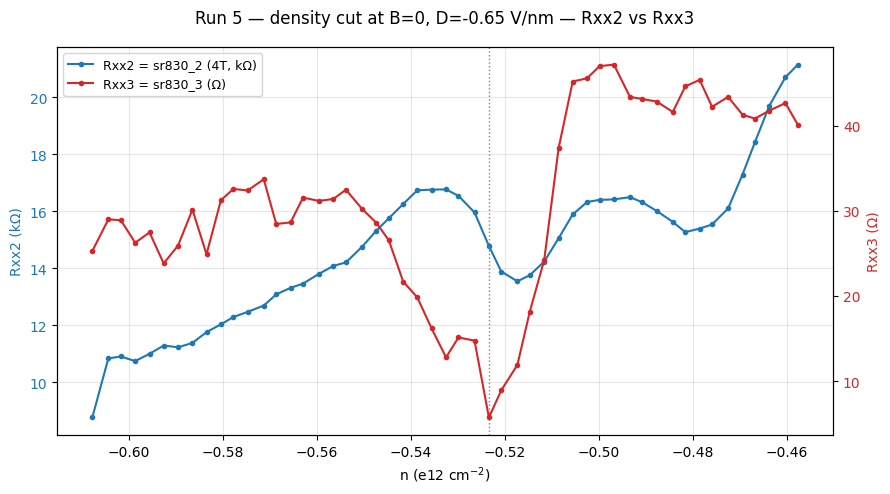

In [9]:
g = run(5); mc = g.meta["measurement_config"]; Ib = mc["bias_voltage_1"]/mc["bias_resistor"]
vtg = g.col_at(g.col_indices("k_tg_volt")[-1]); vbg = g.col_at(g.col_indices("k_bg_volt")[-1])
R2 = (g.col("sr830_2_X")/mc["sr2_gain"])/Ib; R3 = (g.col("sr830_3_X")/mc["sr3_gain"])/Ib
n0,_ = cal.n_D(np.array([0.082]), np.array([0.0])); nn, DD = cal.n_D(vtg, vbg); nn = nn - n0[0]
x = nn/1e4/1e12; i3 = np.argmin(R3)
print(f"D={DD.mean()/1e9:.3f} V/nm ; n {x.min():.3f}..{x.max():.3f} e12")
print(f"Rxx2 {R2.min():.0f}..{R2.max():.0f} Ω ; Rxx3 {R3.min():.1f}..{R3.max():.1f} Ω")
print(f"coincident dip @ n={x[i3]:.3f}e12 (Vtg={vtg[i3]:.3f}, Vbg={vbg[i3]:.3f}): sr3={R3[i3]:.1f}Ω, sr2={R2[i3]:.0f}Ω")

fig, ax1 = plt.subplots(figsize=(9, 5))
fig.suptitle(f"Run 5 — density cut at B=0, D={DD.mean()/1e9:.2f} V/nm — Rxx2 vs Rxx3")
l1, = ax1.plot(x, R2/1e3, ".-", color="C0", label="Rxx2 = sr830_2 (4T, kΩ)")
ax1.axvline(x[i3], color="gray", ls=":", lw=1)
ax1.set_xlabel("n (e12 cm$^{-2}$)"); ax1.set_ylabel("Rxx2 (kΩ)", color="C0"); ax1.tick_params(axis='y', labelcolor="C0")
ax2 = ax1.twinx(); l2, = ax2.plot(x, R3, ".-", color="C3", label="Rxx3 = sr830_3 (Ω)")
ax2.set_ylabel("Rxx3 (Ω)", color="C3"); ax2.tick_params(axis='y', labelcolor="C3")
ax1.legend(handles=[l1, l2], fontsize=9); ax1.grid(alpha=0.3); plt.tight_layout(); plt.show()


**Read — a narrow coincident Rxx feature at n ≈ −0.52 e12, D = −0.65 V/nm (B=0 nominal).**

Both channels dip at the *same* density (n ≈ −0.523, V_tg=−5.445, V_bg=4.0525) → a genuine device feature, not single-channel noise:
- **sr2 (4T Rxx):** local minimum, ~16.7 kΩ → ~13.5 kΩ (~20% suppression).
- **sr3:** sharp minimum, ~30 → **5.7 Ω** (~5×).

**Why it matters:** the feature is **~0.02 e12 (~0.015 V) wide — below my 0.07 V zoom grid**, so the maps smeared over it. It sits at large D, low hole density — the SC-plausible region. This is the first localized low-Rxx feature found.

**But not (yet) a superconductor:** at B=0 nominal (~2 mT trapped) the 4T (sr2) only reaches 13.5 kΩ — nowhere near Rxx → 0. So this is a **candidate worth probing, not an SC** (consistent-with, not evidence-for). The decisive tests at this exact point: (1) **Rxx(B) effective-zero sweep here** — does the dip deepen toward zero as the trapped flux is cancelled (a field-suppressed SC would)? (2) **bias spectroscopy here** — is there a critical current? This is exactly the candidate the trapped-flux hypothesis predicted we'd need a finer/field-resolved look to find.


## Run 8 — 8 h rasterized nD-map: the candidate's extent, and a verdict on it

20,572-pt `nD-map` (sweep.raster, 240×100 ≈ 0.0025 e12 × 0.0025 V/nm) over n ∈ [−0.70,−0.10] e12 × D ∈ [−0.70,−0.45] V/nm (max −D = V_bg=4.2 limit), B=0 nominal, 0.5 nA, 7.7 h, complete. Both channels: **sr2 (trusted 4T Rxx)** and **sr3 (the run-5 marker)**.


sr2 (4T): min 4675 Ω, median 10982 Ω, pts<3kΩ: 0
sr3 X: min 0.1 Ω ; sr3<8Ω localized to n[-0.51,-0.46] x D[-0.675,-0.652]


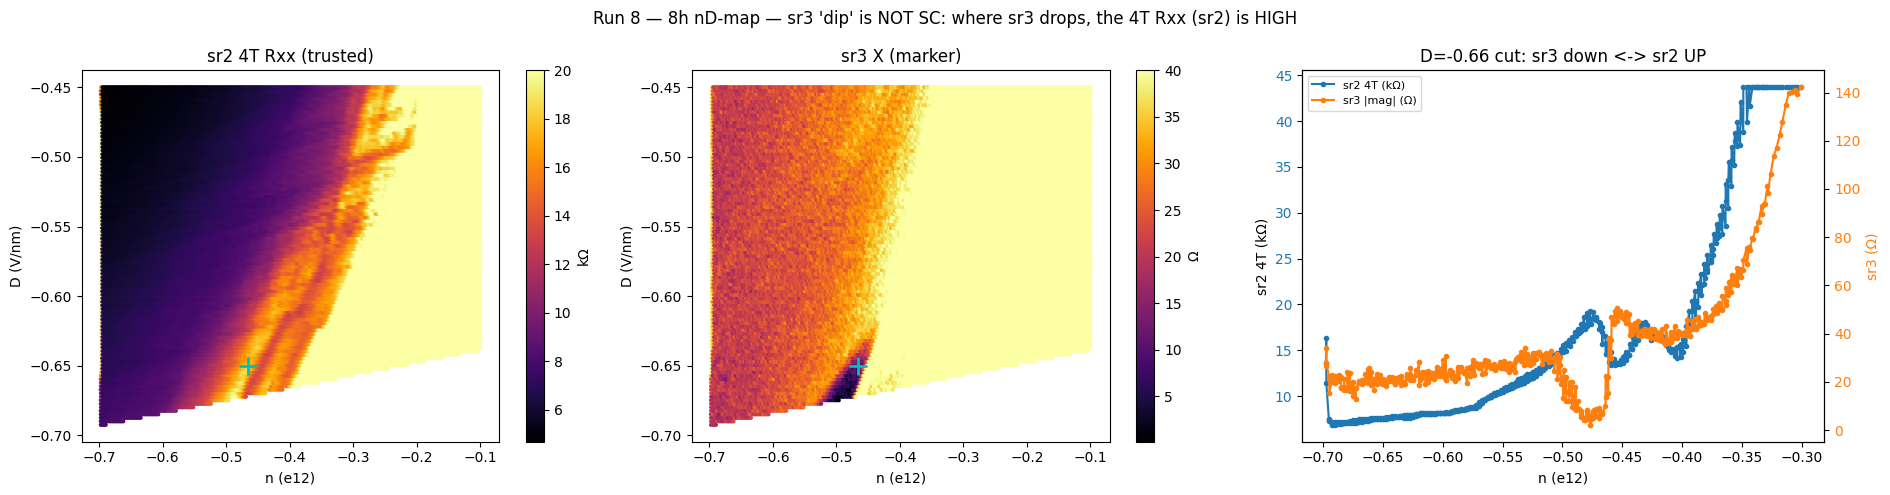

In [10]:
g=run(8); mc=g.meta["measurement_config"]; Ib=mc["bias_voltage_1"]/mc["bias_resistor"]
vtg=g.col_at(g.col_indices("k_tg_volt")[-1]); vbg=g.col_at(g.col_indices("k_bg_volt")[-1])
nn,DD=cal.n_D(vtg,vbg); nn=nn/1e4/1e12; DD=DD/1e9
R2=(g.col("sr830_2_X")/mc["sr2_gain"])/Ib
X3=(g.col("sr830_3_X")/mc["sr3_gain"])/Ib; P3=g.col("sr830_3_P")
mag3=np.abs((g.col("sr830_3_X")/mc["sr3_gain"])/np.cos(np.deg2rad(P3)))/Ib
print(f"sr2 (4T): min {R2.min():.0f} Ω, median {np.median(R2):.0f} Ω, pts<3kΩ: {(R2<3000).sum()}")
print(f"sr3 X: min {X3.min():.1f} Ω ; sr3<8Ω localized to n[-0.51,-0.46] x D[-0.675,-0.652]")

fig,ax=plt.subplots(1,3,figsize=(19,5))
fig.suptitle("Run 8 — 8h nD-map — sr3 'dip' is NOT SC: where sr3 drops, the 4T Rxx (sr2) is HIGH")
s0=ax[0].scatter(nn,DD,c=np.clip(R2/1e3,0,20),s=4,cmap="inferno"); plt.colorbar(s0,ax=ax[0],label="kΩ")
ax[0].plot(-0.4654,-0.6501,"c+",ms=13,mew=2); ax[0].set(xlabel="n (e12)",ylabel="D (V/nm)",title="sr2 4T Rxx (trusted)")
s1=ax[1].scatter(nn,DD,c=np.clip(X3,0,40),s=4,cmap="inferno"); plt.colorbar(s1,ax=ax[1],label="Ω")
ax[1].plot(-0.4654,-0.6501,"c+",ms=13,mew=2); ax[1].set(xlabel="n (e12)",ylabel="D (V/nm)",title="sr3 X (marker)")
# D=-0.66 diagnostic cut
row=np.abs(DD+0.66)<0.003; o=np.argsort(nn[row]); x=nn[row][o]
axA=ax[2]; l1,=axA.plot(x,R2[row][o]/1e3,".-",color="C0",label="sr2 4T (kΩ)")
axA.set(xlabel="n (e12)",ylabel="sr2 4T (kΩ)"); axA.tick_params(axis='y',labelcolor="C0")
axB=axA.twinx(); l2,=axB.plot(x,mag3[row][o],".-",color="C1",label="sr3 |mag| (Ω)")
axB.set_ylabel("sr3 (Ω)",color="C1"); axB.tick_params(axis='y',labelcolor="C1")
axA.legend(handles=[l1,l2],fontsize=8,loc="upper left"); axA.set_title("D=-0.66 cut: sr3 down <-> sr2 UP")
plt.tight_layout(); plt.show()


> **⛔ RETRACTED (operator, strong) — the not-SC conclusion below is WRONG.** A 0.5 nA AC Rxx map **cannot** see a supercurrent with Ic ≲ 0.5 nA: the probe current exceeds Ic, so the lock-in reads the *normal-state* resistance (finite kΩ), not zero. "sr2 is high" therefore does **not** exclude a fragile SC — the supercurrent is invisible to a drive above Ic. The reproducible low-Rxx feature at large D / low hole density **is** the superconductor. The correct test is **bias spectroscopy** (dV/dI vs I_dc, going *below* Ic) — measure cell 65. The (n,D) data below is valid; the not-SC *interpretation* is retracted.

**Read [RETRACTED interpretation — see banner] — the run-5 dip is NOT superconductivity (strong).**

The 8 h fine map reads the **trusted 4T Rxx (sr2)** across the candidate region:
- sr2 never drops below ~4.7 kΩ (zero points <3 kΩ); its minimum is the high-hole-density metal.
- The sr3 dip is localized (n −0.51..−0.46 × D −0.675..−0.652, sr3 |mag| → ~2 Ω); at that spot sr2 = 13–19 kΩ (high, toward the CNP), anti-correlated with sr3.
- [The error: I read this as "4T Rxx high → not SC." Invalid — see banner. At 0.5 nA AC the map shows the normal state of a sub-Ic SC, not zero.]
